# TRABAJO DE INVESTIGACIÓN DE OPERACIONES 1
## SIMULACIÓN DE EVENTOS DISCRETOS — DISTRIBUIDORA "DENLU"

**Objetivo:** validar con simulación el plan de personal obtenido en **`Denlu.ipynb`** (diagnóstico con colas $M/M/c$ y MILP con OR-Tools) y medir su robustez.

Este cuaderno parte de los resultados de `Denlu.ipynb`: la tabla del diagnóstico por hora (celda 1), el modelo MILP (celda 7) y el análisis de ROI (celda 11). Los capítulos 1 a 3 los reproducen y comprueban que coinciden; desde el capítulo 4 empieza la simulación.

| Capítulo | Pregunta que responde |
|---|---|
| 1–3. Datos, MILP y ROI de `Denlu.ipynb` | ¿De qué se parte? |
| 4–5. Modelo, calibración y validación | ¿El modelo se parece al almacén real? |
| 6. Plan actual vs. óptimo | ¿El plan elimina de verdad la pérdida de ruta? ¿Se cumple el 95 % de recuperación? |
| 7–8. Demanda y ausentismo | ¿Qué tan robusto es? |
| 9–10. $\rho$ objetivo y margen bruto | ¿Conviene otro nivel de servicio? |
| 11. Conclusiones | Resumen calculado con los resultados de arriba |

**Simulador interactivo** (animación de un día y comparación del año completo): <https://efustion23.github.io/denlu-simulacion/>

## 1. Datos de partida (resultados de `Denlu.ipynb`)

La tabla por hora es la salida de la celda 1 de `Denlu.ipynb` (8 012 pedidos de 2025, 299 días operativos, 3 despachadores) y los totales, los de su celda 11.

In [1]:
%pip install -q --disable-pip-version-check simpy ortools

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import simpy
from ortools.linear_solver import pywraplp

# Paleta compartida con el simulador web: azul acero = plan elegido, gris = situación actual
COLOR = {"plan": "#2d5c88", "actual": "#a3a7a4", "hist": "#c19463", "alerta": "#c4242a", "ok": "#1e7b4f",
         "aviso": "#f2b705", "tinta": "#141617", "tinta2": "#5b5f5c", "linea": "#e3e5e1"}
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": COLOR["linea"], "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.labelcolor": COLOR["tinta2"], "xtick.color": COLOR["tinta2"], "ytick.color": COLOR["tinta2"],
    "text.color": COLOR["tinta"], "legend.frameon": False, "font.size": 10.5,
})
soles = lambda v: f"S/ {v:,.0f}"
k_soles = lambda v, _=None: f"{v / 1000:,.0f} mil"

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Parámetros analíticos del sistema actual (los mismos de Denlu.ipynb)
MU_MIN = 44.5                                # tiempo medio de despacho (min/pedido), exponencial
MU_H = 60.0 / MU_MIN                         # tasa de servicio individual (~1.348 ped/h)
C_ACTUAL = 3                                 # despachadores fijos hoy
DIAS = 299                                   # días operativos por año
HORAS = list(range(8, 18))

# Salida de la celda 1 de Denlu.ipynb (diagnóstico por hora)
diag = pd.DataFrame({
    "Hora_Int": HORAS,
    "Lambda (Ped/Hr)": [1.599, 6.742, 6.268, 3.064, 1.324, 1.836, 2.786, 1.505, 1.107, 0.565],
    "Espera Media (Min)": [4.54, 40.77, 39.46, 4.62, 4.85, 4.55, 4.75, 4.40, 4.53, 4.77],
    "Pérdida Ruta (%)": [0.0, 75.15, 74.81, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0],
})
# Salida de la celda 11 de Denlu.ipynb: 10.00 % de cancelación y S/ 620,042.58 de venta perdida al año
TOTALES = {"pedidos": 8012, "cancelados": 801, "venta_perdida": 620_042.58}

diag["Hora"] = diag["Hora_Int"].map(lambda h: f"{h:02d}:00")
diag["Rho (Utilización)"] = [0.395, 1.667, 1.549, 0.757, 0.327, 0.454, 0.689, 0.372, 0.274, 0.140]   # también de la celda 1
diag = diag[["Hora", "Hora_Int", "Lambda (Ped/Hr)", "Rho (Utilización)", "Espera Media (Min)", "Pérdida Ruta (%)"]]
# Comprobación: ρ = λ / (3 μ), con la diferencia de redondeo de usar λ ya redondeado
assert np.allclose(diag["Rho (Utilización)"], diag["Lambda (Ped/Hr)"] / (C_ACTUAL * MU_H), atol=0.0011)

display(diag.drop(columns="Hora_Int").style.hide(axis="index")
        .format({"Lambda (Ped/Hr)": "{:.3f}", "Rho (Utilización)": "{:.3f}", "Espera Media (Min)": "{:.2f}", "Pérdida Ruta (%)": "{:.2f}"})
        .apply(lambda r: ["background-color: #fbe3e1" if r["Rho (Utilización)"] >= 1 else "" for _ in r], axis=1))

Hora,Lambda (Ped/Hr),Rho (Utilización),Espera Media (Min),Pérdida Ruta (%)
08:00,1.599,0.395,4.54,0.00
09:00,6.742,1.667,40.77,75.15
10:00,6.268,1.549,39.46,74.81
11:00,3.064,0.757,4.62,0.00
12:00,1.324,0.327,4.85,0.00
13:00,1.836,0.454,4.55,0.00
14:00,2.786,0.689,4.75,0.00
15:00,1.505,0.372,4.40,0.00
16:00,1.107,0.274,4.53,0.00
17:00,0.565,0.140,4.77,0.00


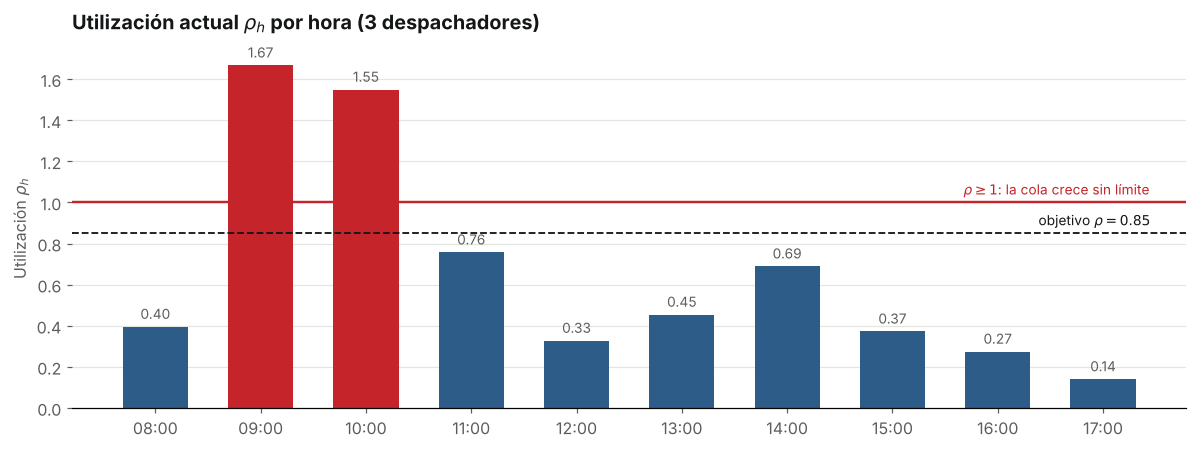

In [3]:
fig, ax = plt.subplots()
rho = diag["Rho (Utilización)"]
colores = [COLOR["alerta"] if r >= 1 else COLOR["aviso"] if r > 0.85 else COLOR["plan"] for r in rho]
barras = ax.bar(diag["Hora"], rho, color=colores, width=0.62)
ax.bar_label(barras, fmt="%.2f", padding=3, color=COLOR["tinta2"], fontsize=9)
ax.axhline(0.85, color=COLOR["tinta"], ls="--", lw=1.2)
ax.axhline(1.00, color=COLOR["alerta"], lw=1.6)
ax.text(9.45, 0.87, r"objetivo $\rho = 0.85$", ha="right", va="bottom", fontsize=9, color=COLOR["tinta"])
ax.text(9.45, 1.02, r"$\rho \geq 1$: la cola crece sin límite", ha="right", va="bottom", fontsize=9, color=COLOR["alerta"])
ax.set_title(r"Utilización actual $\rho_h$ por hora (3 despachadores)")
ax.set_ylabel(r"Utilización $\rho_h$")
plt.tight_layout(); plt.show()

## 2. Modelo MILP (el mismo de `Denlu.ipynb`)

Mismas variables, costos y restricciones que la celda 7 de `Denlu.ipynb`. Aquí la cobertura de cada turno se define una sola vez (`TURNOS`) para poder re-optimizar el MILP con otros $\rho$ en el capítulo 9. Se comprueba que con $\rho = 0.85$ da el mismo plan y el mismo costo.

In [4]:
C_FT, C_PT = 1373.50, 686.76                 # costo mensual por trabajador (S/)
TURNOS = {                                   # horas (inicio de cada intervalo) en que trabaja cada turno
    "FT-1": [8, 9, 10, 11, 13, 14, 15, 16],  # 08-17, almuerzo 12-13
    "FT-2": [8, 9, 10, 11, 12, 14, 15, 16],  # 08-17, almuerzo 13-14
    "FT-3": [9, 10, 11, 12, 13, 15, 16, 17], # 09-18, almuerzo 14-15
    "PT-1": [9, 10, 11, 12],                 # 09-13
    "PT-2": [10, 11, 12, 13],                # 10-14
    "PT-3": [14, 15, 16, 17],                # 14-18
}
es_parcial = lambda t: t.startswith("PT")
LAMBDA = dict(zip(diag["Hora_Int"], diag["Lambda (Ped/Hr)"]))        # ped/h, del diagnóstico


def requeridos(rho):
    # D_h: despachadores mínimos por hora para que la utilización no pase de rho (mínimo 1 por seguridad)
    return {h: max(1, int(np.ceil(LAMBDA[h] / (rho * MU_H)))) for h in HORAS}


def optimizar(rho):
    # MILP de turnos: mínimo costo de planilla que cubre D_h en cada hora y respeta el 40 % de part-time
    req = requeridos(rho)
    s = pywraplp.Solver.CreateSolver("SCIP")
    x = {t: s.IntVar(0, 10, t) for t in TURNOS}
    for h in HORAS:
        s.Add(sum(x[t] for t in x if h in TURNOS[t]) >= req[h], f"NivelServicio_{h:02d}")
    ft = sum(v for t, v in x.items() if not es_parcial(t))
    pt = sum(v for t, v in x.items() if es_parcial(t))
    s.Add(-0.40 * ft + 0.60 * pt <= 0, "Proporcion_PT_Max_40")
    s.Minimize(C_FT * ft + C_PT * pt)
    assert s.Solve() == pywraplp.Solver.OPTIMAL, "El MILP no tiene solución"
    return {t: round(v.solution_value()) for t, v in x.items() if v.solution_value() > 0.5}


def costo_mensual(plan):
    return sum(n * (C_PT if es_parcial(t) else C_FT) for t, n in plan.items())


RHO_OBJETIVO = 0.85
req_h = requeridos(RHO_OBJETIVO)
plan_optimo = optimizar(RHO_OBJETIVO)
costo_optimo = costo_mensual(plan_optimo)
assert abs(costo_optimo - 6867.52) < 0.01, "El costo óptimo difiere del de Denlu.ipynb (S/ 6,867.52)"
assert plan_optimo == {"FT-1": 3, "FT-3": 1, "PT-1": 2}, "El plan difiere del de Denlu.ipynb"

print("=== REQUERIMIENTO MÍNIMO DE DESPACHADORES (D_h) ===")
print("  ".join(f"{h:02d}h: {n}" for h, n in req_h.items()))
print(f"\n=== SOLUCIÓN ÓPTIMA (rho <= {RHO_OBJETIVO}) ===")
print(f"Costo de planilla del almacén: {soles(costo_optimo)} al mes  ({soles(12 * costo_optimo)} al año)")
for t in TURNOS:
    print(f"  {t}: {plan_optimo.get(t, 0)} despachador(es)")

=== REQUERIMIENTO MÍNIMO DE DESPACHADORES (D_h) ===
08h: 2  09h: 6  10h: 6  11h: 3  12h: 2  13h: 2  14h: 3  15h: 2  16h: 1  17h: 1

=== SOLUCIÓN ÓPTIMA (rho <= 0.85) ===
Costo de planilla del almacén: S/ 6,868 al mes  (S/ 82,410 al año)
  FT-1: 3 despachador(es)
  FT-2: 0 despachador(es)
  FT-3: 1 despachador(es)
  PT-1: 2 despachador(es)
  PT-2: 0 despachador(es)
  PT-3: 0 despachador(es)


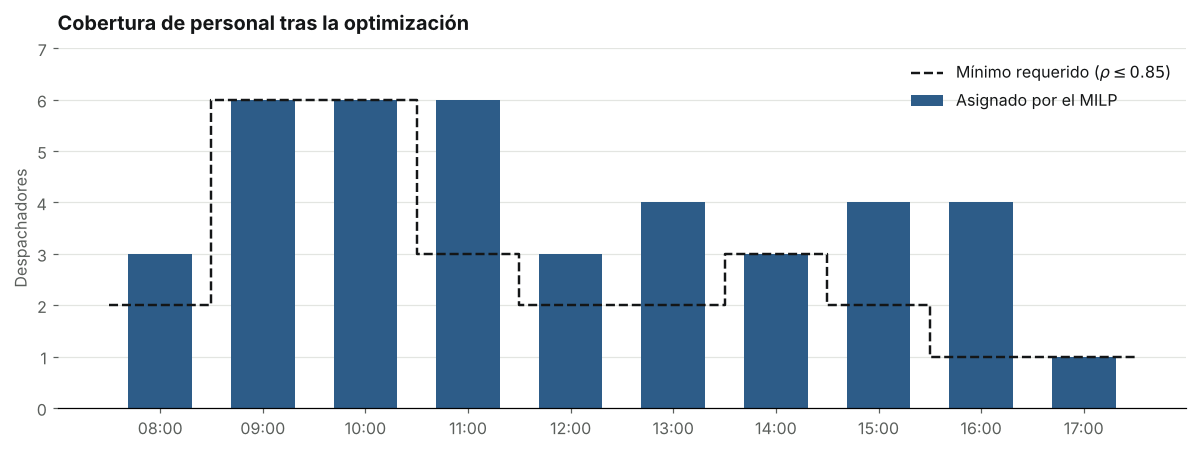

In [5]:
def personal_por_hora(plan, turnos=TURNOS):
    # Despachadores en turno en cada hora para un plan {turno: cantidad}
    return {h: sum(n for t, n in plan.items() if h in turnos[t]) for h in HORAS}


cobertura = personal_por_hora(plan_optimo)
comparativo = pd.DataFrame({"Hora": [f"{h:02d}:00" for h in HORAS], "Mín. requerido": [req_h[h] for h in HORAS],
                            "Asignado óptimo": [cobertura[h] for h in HORAS]})
comparativo["Diferencia"] = comparativo["Asignado óptimo"] - comparativo["Mín. requerido"]

fig, ax = plt.subplots()
x = np.arange(len(HORAS))
ax.bar(x, comparativo["Asignado óptimo"], 0.62, color=COLOR["plan"], label="Asignado por el MILP")
ax.step(np.r_[x - 0.5, x[-1] + 0.5], np.r_[comparativo["Mín. requerido"], comparativo["Mín. requerido"].iloc[-1]],
        where="post", color=COLOR["tinta"], ls="--", lw=1.6, label=r"Mínimo requerido ($\rho \leq 0.85$)")
ax.set_xticks(x, comparativo["Hora"]); ax.set_yticks(range(0, int(comparativo["Asignado óptimo"].max()) + 2))
ax.set_title("Cobertura de personal tras la optimización"); ax.set_ylabel("Despachadores"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()

## 3. ROI de `Denlu.ipynb` (supuesto: se recupera el 95 % de la venta perdida)

Mismo cálculo que la celda 11 de `Denlu.ipynb`. El 95 % es un supuesto: la simulación lo pone a prueba en el capítulo 6.

In [6]:
RECUPERACION_SUPUESTA = 0.95
tasa_cancelados = 100 * TOTALES["cancelados"] / TOTALES["pedidos"]
ventas_perdidas_anuales = TOTALES["venta_perdida"]
TICKET = ventas_perdidas_anuales / TOTALES["cancelados"]        # S/ por pedido cancelado

planilla_actual_anual = C_ACTUAL * C_FT * 12
planilla_optima_anual = costo_optimo * 12
inversion_adicional = planilla_optima_anual - planilla_actual_anual
recuperacion_estimada = ventas_perdidas_anuales * RECUPERACION_SUPUESTA
beneficio_neto = recuperacion_estimada - inversion_adicional
roi_analitico = 100 * beneficio_neto / inversion_adicional

print("=== RETORNO DE INVERSIÓN (supuesto de recuperación del 95 %) ===")
print(f"Tasa de cancelación de pedidos hoy:       {tasa_cancelados:.2f} %")
print(f"Venta perdida anual por cancelación:      {soles(ventas_perdidas_anuales)}   (ticket promedio {TICKET:,.2f} por pedido)")
print(f"Inversión adicional de planilla:          {soles(inversion_adicional)} al año")
print(f"Ventas recuperadas (95 %):                {soles(recuperacion_estimada)} al año")
print("-" * 62)
print(f"BENEFICIO NETO ANUAL:                     {soles(beneficio_neto)}")
print(f"ROI:                                      {roi_analitico:,.0f} %")

=== RETORNO DE INVERSIÓN (supuesto de recuperación del 95 %) ===
Tasa de cancelación de pedidos hoy:       10.00 %
Venta perdida anual por cancelación:      S/ 620,043   (ticket promedio 774.09 por pedido)
Inversión adicional de planilla:          S/ 32,964 al año
Ventas recuperadas (95 %):                S/ 589,040 al año
--------------------------------------------------------------
BENEFICIO NETO ANUAL:                     S/ 556,076
ROI:                                      1,687 %


El modelo de colas $M/M/c$ analiza cada hora **por separado y en estado estable**. En la realidad la cola que se forma a las 9–10 h **se arrastra** a las horas siguientes, los almuerzos reducen la capacidad y la demanda varía día a día. La simulación (SimPy) reproduce pedido por pedido una jornada completa (08:00–18:00) durante 299 días operativos para responder:

1. ¿El plan óptimo realmente elimina la pérdida de ruta? ¿Se cumple el 95 % de recuperación del ROI?
2. ¿Hasta qué crecimiento de la demanda aguanta el plan?
3. ¿Qué pasa si falta personal (ausentismo)?
4. ¿Es $\rho = 0.85$ el mejor objetivo, considerando planilla + horas extra + ventas perdidas?
5. ¿Cambia la decisión si la venta perdida se valora a su margen bruto y no a precio de venta?

**Datos de entrada:** todo viene de los capítulos 1–3 (es decir, de `Denlu.ipynb`) (`LAMBDA`, `MU_MIN`, `TURNOS`, `plan_optimo`, `TICKET`, costos y las esperas y pérdidas históricas por hora).

## 4. Modelo de simulación

**Entidades:** pedidos. **Recursos:** despachadores. **Reloj:** minutos desde las 08:00.

| Elemento | Supuesto |
|---|---|
| Llegadas | Proceso de Poisson no homogéneo: tasa $\lambda_h$ constante dentro de cada hora |
| Servicio | Exponencial, media 44.5 min (consistente con el $M/M/c$ del diagnóstico) |
| Disciplina | FIFO, un solo almacén con $c_h$ despachadores activos |
| Turnos | Los del MILP, con almuerzo. Al salir (almuerzo o fin de turno) el despachador **termina el pedido en curso** |
| Situación actual | 3 despachadores de 08:00 a 18:00 sin descontar almuerzo (igual que el diagnóstico; escenario optimista) |
| Pérdida de ruta | Si un pedido espera más de **T** min, su camión sale sin él |
| Cancelación | Tras perder la ruta, el cliente cancela con probabilidad **p**; si no, sigue esperando y se despacha para otra ruta |
| Cierre | Lo pendiente a las 18:00 se despacha con horas extra (personal de las 17 h, mínimo 1) |
| Horas extra | Cada minuto trabajado después de las 18:00 se paga como hora extra: S/ 5.34/h (sueldo base / 240 h + 25 %) |
| Venta perdida | Cada cancelación pierde el ticket promedio histórico, valorado al margen bruto (`MARGEN`; 100 % = precio de venta) |

**T** y **p** no se conocen: se **calibran** para que la situación actual simulada reproduzca los indicadores de 2025.

Para modelar la capacidad variable se usa un `PriorityResource`: cuando un despachador sale de turno, un "bloqueo" de prioridad alta ocupa su puesto apenas termina su pedido actual.

In [7]:
# --- Parámetros de la simulación (los que no vienen de Denlu.ipynb) ---
CIERRE = 600                                  # 18:00, en minutos desde las 08:00
COSTO_HORA_EXTRA = 1025 / 240 * 1.25          # hora simple del sueldo base + 25 % (D.S. 007-2002-TR)
MARGEN = 1.0                                  # margen bruto de un pedido; 1.0 = venta perdida a precio de venta
R = 10                                        # réplicas (años simulados) por escenario
T_STUDENT = 2.262                             # t(0.975, R-1 = 9) para intervalos de confianza al 95 %

# --- Referencias históricas 2025 (diagnóstico de Denlu.ipynb) ---
HIST_ESPERA = dict(zip(diag["Hora_Int"], diag["Espera Media (Min)"]))
HIST_PERDIDA = dict(zip(diag["Hora_Int"], diag["Pérdida Ruta (%)"]))
HIST_CANCEL = tasa_cancelados                 # % de pedidos cancelados
HIST_PERDIDA_TOTAL = sum(HIST_PERDIDA[h] * LAMBDA[h] for h in HORAS) / sum(LAMBDA.values())

# La situación actual es un "turno" más: 3 despachadores de 08 a 18 sin descontar almuerzo
TURNOS_SIM = {**TURNOS, "ACTUAL": list(HORAS)}
PLAN_ACTUAL = {"ACTUAL": C_ACTUAL}
PLAN_OPTIMO = dict(plan_optimo)

print(f"Pedidos/día esperados: {sum(LAMBDA.values()):.1f} | Ticket promedio de un pedido cancelado: S/ {TICKET:,.2f}")
print(f"Pérdida de ruta histórica sobre el total de pedidos: {HIST_PERDIDA_TOTAL:.1f} %  |  cancelados: {HIST_CANCEL:.2f} %")
print(f"Costo de una hora extra: S/ {COSTO_HORA_EXTRA:.2f}")
print("Despachadores por hora, plan óptimo:", personal_por_hora(PLAN_OPTIMO, TURNOS_SIM))

Pedidos/día esperados: 26.8 | Ticket promedio de un pedido cancelado: S/ 774.09
Pérdida de ruta histórica sobre el total de pedidos: 36.4 %  |  cancelados: 10.00 %
Costo de una hora extra: S/ 5.34
Despachadores por hora, plan óptimo: {8: 3, 9: 6, 10: 6, 11: 6, 12: 3, 13: 4, 14: 3, 15: 4, 16: 4, 17: 1}


In [8]:
def simular_dia(personal_h, lam, T, p_cancel, rng):
    # Devuelve una fila por pedido: (hora de llegada, espera en min, perdió ruta, cancelado)
    # y los minutos-persona trabajados después del cierre de las 18:00 (horas extra).
    env = simpy.Environment()
    cap = max(1, max(personal_h.values()))
    almacen = simpy.PriorityResource(env, capacity=cap)
    registros = []
    extra_min = 0.0

    def control_turnos():
        bloqueos = []
        for n in [personal_h[h] for h in HORAS] + [max(1, personal_h[17])]:   # último = horas extra
            while len(bloqueos) < cap - n:
                bloqueos.append(almacen.request(priority=-1))
            while len(bloqueos) > cap - n:
                b = bloqueos.pop()
                almacen.release(b) if b.triggered else b.cancel()
            yield env.timeout(60)

    def pedido(h):
        nonlocal extra_min
        llegada = env.now
        req = almacen.request(priority=0)
        yield req | env.timeout(T)
        perdio_ruta = not req.triggered
        if perdio_ruta and rng.random() < p_cancel:
            req.cancel()
            registros.append((h, T, True, True))
            return
        yield req
        registros.append((h, env.now - llegada, perdio_ruta, False))
        duracion = rng.exponential(MU_MIN)
        extra_min += max(0.0, env.now + duracion - max(env.now, CIERRE))
        yield env.timeout(duracion)
        almacen.release(req)

    llegadas = sorted((60 * (h - 8) + u, h) for h in HORAS for u in rng.uniform(0, 60, rng.poisson(lam[h])))

    def generador():
        for t, h in llegadas:
            yield env.timeout(t - env.now)
            env.process(pedido(h))

    env.process(control_turnos())
    env.process(generador())
    env.run()
    return registros, extra_min


def simular_anio(plan, T, p_cancel, seed, crecimiento=0.0, ausentismo=0.0):
    # Un año = 299 jornadas independientes. Ausentismo: cada trabajador falta con esa probabilidad diaria.
    rng = np.random.default_rng(seed)
    lam = {h: LAMBDA[h] * (1 + crecimiento) for h in HORAS}
    filas, extra_min = [], 0.0
    for _ in range(DIAS):
        presentes = {t: rng.binomial(n, 1 - ausentismo) for t, n in plan.items()}
        registros, extra = simular_dia(personal_por_hora(presentes, TURNOS_SIM), lam, T, p_cancel, rng)
        filas += registros
        extra_min += extra
    df_anio = pd.DataFrame(filas, columns=["hora", "espera", "perdio_ruta", "cancelado"])
    df_anio.attrs["horas_extra"] = extra_min / 60
    return df_anio


def indicadores(df_anio, plan):
    venta_perdida = df_anio["cancelado"].sum() * TICKET
    planilla = 12 * costo_mensual(plan)
    horas_extra = df_anio.attrs["horas_extra"]
    return {"Pedidos": len(df_anio),
            "Espera media (min)": df_anio["espera"].mean(),
            "Espera 9-11h (min)": df_anio.loc[df_anio["hora"].isin([9, 10]), "espera"].mean(),
            "Pérdida ruta (%)": 100 * df_anio["perdio_ruta"].mean(),
            "Cancelados (%)": 100 * df_anio["cancelado"].mean(),
            "Venta perdida (S/)": venta_perdida,
            "Margen perdido (S/)": venta_perdida * MARGEN,
            "Horas extra (h/año)": horas_extra,
            "Costo horas extra (S/)": horas_extra * COSTO_HORA_EXTRA,
            "Planilla anual (S/)": planilla,
            "Costo total (S/)": planilla + horas_extra * COSTO_HORA_EXTRA + venta_perdida * MARGEN}


def replicar(plan, T, p, **kw):
    # Mismas semillas en todos los escenarios = números aleatorios comunes (reduce la varianza al comparar)
    return pd.DataFrame([indicadores(simular_anio(plan, T, p, seed=s, **kw), plan) for s in range(R)])


def media_ic(reps):
    return pd.DataFrame({"Media": reps.mean(), "± IC 95%": T_STUDENT * reps.std() / np.sqrt(R)})


etiquetas = [f"{h:02d}h" for h in HORAS]
x = np.arange(len(HORAS))


def barras_por_hora(ax, series, titulo, ylabel, anotar=None):
    # Barras agrupadas por hora de llegada. series = {nombre: (valores, color)}
    ancho = 0.8 / len(series)
    for i, (nombre, (valores, color)) in enumerate(series.items()):
        ax.bar(x + (i - (len(series) - 1) / 2) * ancho, valores, ancho * 0.92, label=nombre, color=color)
    ax.set_xticks(x, etiquetas); ax.set_title(titulo); ax.set_ylabel(ylabel); ax.legend()
    if anotar:
        ax.annotate(anotar[0], xy=anotar[1], xytext=anotar[2], fontsize=9, color=COLOR["alerta"],
                    arrowprops=dict(arrowstyle="-", color=COLOR["alerta"], lw=1), ha="center")

## 5. Calibración y validación del modelo

Se buscan **T** (umbral de espera para perder la ruta) y **p** (probabilidad de cancelar tras perderla) que hagan que la operación actual simulada reproduzca los dos indicadores globales de 2025:

* Pérdida de ruta sobre el total de pedidos ≈ 36.4 %
* Pedidos cancelados ≈ 10 %

Se minimiza el error cuadrático sobre una grilla, promediando 4 años simulados por punto.

In [9]:
grilla = []
for T in [15, 20, 25]:
    for p in [0.24, 0.26, 0.28, 0.30, 0.32]:
        sims = pd.concat([simular_anio(PLAN_ACTUAL, T, p, seed=1000 + s) for s in range(4)])
        perdida, cancel = 100 * sims["perdio_ruta"].mean(), 100 * sims["cancelado"].mean()
        grilla.append({"T": T, "p": p, "Pérdida (%)": perdida, "Cancel (%)": cancel,
                       "Error": (perdida - HIST_PERDIDA_TOTAL) ** 2 + (cancel - HIST_CANCEL) ** 2})
grilla = pd.DataFrame(grilla)
mejor = grilla.loc[grilla["Error"].idxmin()]
T_CAL, P_CAL = float(mejor["T"]), float(mejor["p"])

display(grilla.pivot(index="T", columns="p", values="Error").round(1)
        .style.background_gradient(cmap="Blues_r").set_caption("Error de calibración (menor = mejor)"))
print(f"Calibrado: T = {T_CAL:.0f} min, p = {P_CAL:.2f} -> pérdida {mejor['Pérdida (%)']:.1f} %, cancelados {mejor['Cancel (%)']:.1f} %")

p,0.240000,0.260000,0.280000,0.300000,0.320000
T,,,,,
15,18.900000,14.900000,11.100000,8.800000,9.100000
20,1.500000,0.300000,0.300000,2.600000,2.900000
25,4.800000,2.700000,3.900000,14.800000,6.000000


Calibrado: T = 20 min, p = 0.28 -> pérdida 36.8 %, cancelados 10.3 %


,8,9,10,11,12,13,14,15,16,17
Espera hist. (min),4.5,40.8,39.5,4.6,4.8,4.6,4.8,4.4,4.5,4.8
Espera sim. (min),0.5,15.3,36.4,37.4,23.0,12.1,10.0,7.6,3.9,0.9
Pérdida hist. (%),0.0,75.2,74.8,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Pérdida sim. (%),1.1,31.2,65.0,60.4,39.2,21.7,18.7,14.4,7.7,2.1


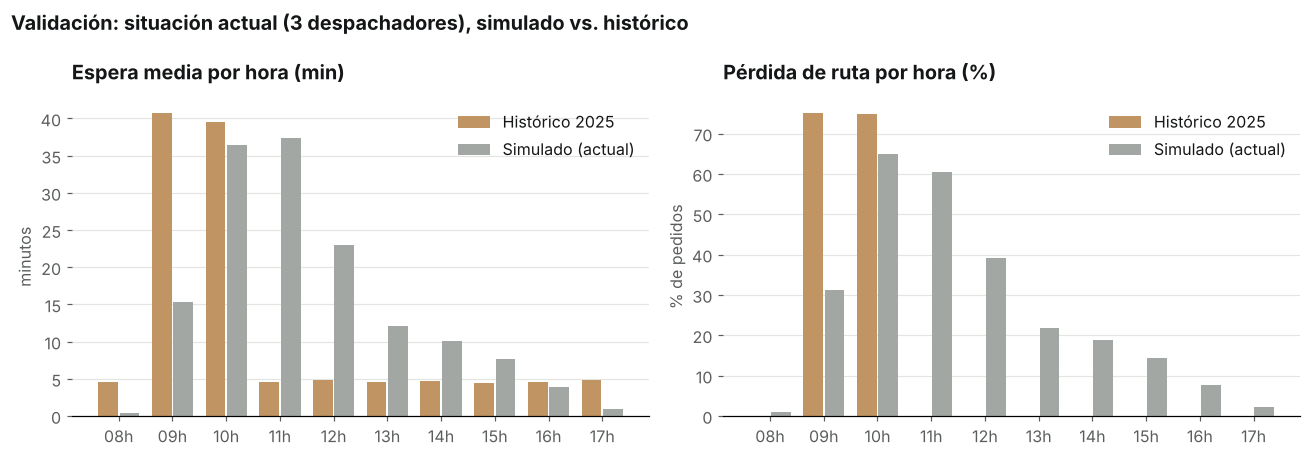

**Lectura.** Los totales anuales coinciden: pérdida de ruta **36.6 %** simulada vs. 36.4 % histórica, cancelación **10.3 %** vs. 10.0 %. Hora por hora el ajuste es parcial (error cuadrático medio: 29 puntos de pérdida y 15 min de espera). En el histórico la pérdida aparece solo a las 9–10 h y desaparece de golpe a las 11 h, mientras que en la simulación la cola formada en el pico **se arrastra** hasta las 15 h (pérdida simulada de 60 % a las 11 h). Una cola real con $\rho > 1$ durante dos horas seguidas se comporta así, y es el efecto que el análisis $M/M/c$ hora por hora no puede ver.

Además, la espera histórica fuera del pico es plana (≈ 4.6 min) aunque $\rho_h$ va de 0.14 a 0.76; esa constante parece un tiempo de preparación o confirmación fijo que el modelo no incluye. Con el CSV completo (minuto de llegada, tiempo de servicio) se podrían calibrar ambas cosas.

In [10]:
# Validación hora por hora: situación actual simulada vs. histórico 2025
sim_actual = pd.concat([simular_anio(PLAN_ACTUAL, T_CAL, P_CAL, seed=s) for s in range(R)])
por_hora = sim_actual.groupby("hora").agg(espera=("espera", "mean"), perdida=("perdio_ruta", "mean"))
sim_perdida = 100 * por_hora["perdida"]
validacion = pd.DataFrame({"Espera hist. (min)": HIST_ESPERA, "Espera sim. (min)": por_hora["espera"],
                           "Pérdida hist. (%)": HIST_PERDIDA, "Pérdida sim. (%)": sim_perdida})
display(validacion.round(1).T)

rmse_perdida = float(np.sqrt(((sim_perdida - pd.Series(HIST_PERDIDA)) ** 2).mean()))
rmse_espera = float(np.sqrt(((por_hora["espera"] - pd.Series(HIST_ESPERA)) ** 2).mean()))
tot_perdida, tot_cancel = 100 * sim_actual["perdio_ruta"].mean(), 100 * sim_actual["cancelado"].mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
barras_por_hora(ax[0], {"Histórico 2025": ([HIST_ESPERA[h] for h in HORAS], COLOR["hist"]),
                        "Simulado (actual)": (por_hora["espera"], COLOR["actual"])}, "Espera media por hora (min)", "minutos")
barras_por_hora(ax[1], {"Histórico 2025": ([HIST_PERDIDA[h] for h in HORAS], COLOR["hist"]),
                        "Simulado (actual)": (sim_perdida, COLOR["actual"])}, "Pérdida de ruta por hora (%)", "% de pedidos")
fig.suptitle("Validación: situación actual (3 despachadores), simulado vs. histórico", x=0.01, ha="left", fontweight="bold", fontsize=13)
plt.tight_layout(); plt.show()

fuera_pico = [h for h in HORAS if h not in (9, 10) and sim_perdida[h] > 10 and HIST_PERDIDA[h] == 0]
display(Markdown(
    f"**Lectura.** Los totales anuales coinciden: pérdida de ruta **{tot_perdida:.1f} %** simulada vs. {HIST_PERDIDA_TOTAL:.1f} % histórica, "
    f"cancelación **{tot_cancel:.1f} %** vs. {HIST_CANCEL:.1f} %. Hora por hora el ajuste es parcial (error cuadrático medio: "
    f"{rmse_perdida:.0f} puntos de pérdida y {rmse_espera:.0f} min de espera). "
    f"En el histórico la pérdida aparece solo a las 9–10 h y desaparece de golpe a las 11 h, mientras que en la simulación la cola formada en el pico "
    f"**se arrastra** hasta {f'las {max(fuera_pico)} h' if fuera_pico else 'el mediodía'} "
    f"(pérdida simulada de {sim_perdida[11]:.0f} % a las 11 h). Una cola real con $\\rho > 1$ durante dos horas seguidas se comporta así, y es el efecto "
    f"que el análisis $M/M/c$ hora por hora no puede ver.\n\n"
    f"Además, la espera histórica fuera del pico es plana (≈ {np.mean([HIST_ESPERA[h] for h in HORAS if h not in (9, 10)]):.1f} min) "
    f"aunque $\\rho_h$ va de {diag['Rho (Utilización)'].min():.2f} a {diag.loc[~diag['Hora_Int'].isin([9, 10]), 'Rho (Utilización)'].max():.2f}; "
    f"esa constante parece un tiempo de preparación o confirmación fijo que el modelo no incluye. "
    f"Con el CSV completo (minuto de llegada, tiempo de servicio) se podrían calibrar ambas cosas."))

## 6. Escenario 1 — Situación actual vs. plan óptimo (MILP, $\rho = 0.85$)

In [11]:
reps = {"Actual": replicar(PLAN_ACTUAL, T_CAL, P_CAL), "Óptimo": replicar(PLAN_OPTIMO, T_CAL, P_CAL)}
tabla = pd.concat({k: media_ic(v) for k, v in reps.items()}, axis=1)
display(tabla.style.format("{:,.2f}"))

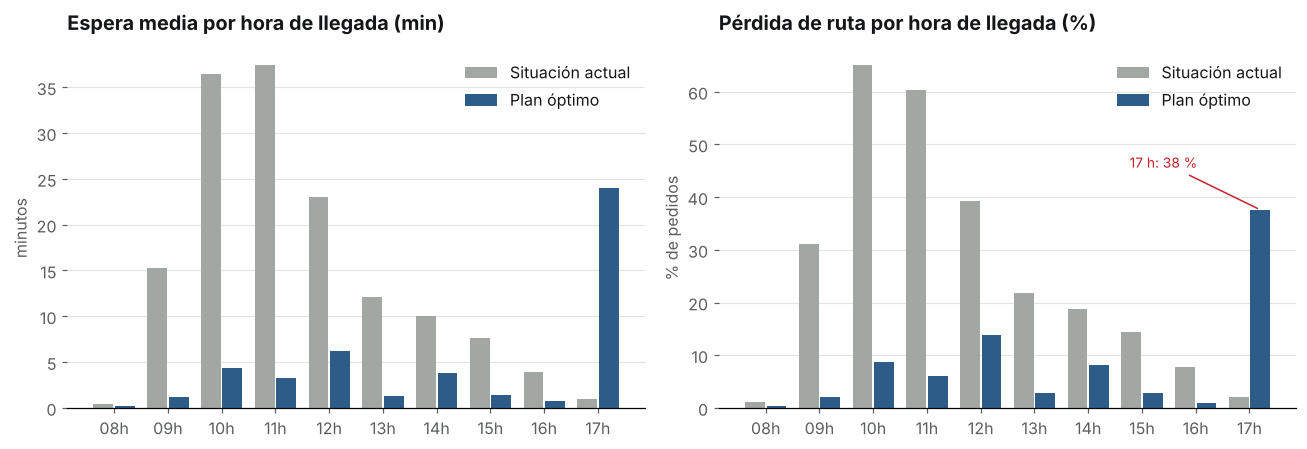

In [12]:
sim_opt = pd.concat([simular_anio(PLAN_OPTIMO, T_CAL, P_CAL, seed=s) for s in range(R)])
perdida_opt = 100 * sim_opt.groupby("hora")["perdio_ruta"].mean()
espera_opt = sim_opt.groupby("hora")["espera"].mean()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
barras_por_hora(ax[0], {"Situación actual": (por_hora["espera"], COLOR["actual"]), "Plan óptimo": (espera_opt, COLOR["plan"])},
                "Espera media por hora de llegada (min)", "minutos")
peor_h = int(perdida_opt.idxmax())
barras_por_hora(ax[1], {"Situación actual": (sim_perdida, COLOR["actual"]), "Plan óptimo": (perdida_opt, COLOR["plan"])},
                "Pérdida de ruta por hora de llegada (%)", "% de pedidos",
                anotar=(f"{peor_h} h: {perdida_opt[peor_h]:.0f} %", (HORAS.index(peor_h) + 0.2, perdida_opt[peor_h]),
                        (HORAS.index(peor_h) - 1.6, perdida_opt[peor_h] + 8)) if perdida_opt[peor_h] > 15 else None)
plt.tight_layout(); plt.show()

In [13]:
# ROI recalculado con la simulación (el análisis analítico supone 95 % de recuperación)
act, opt = reps["Actual"].mean(), reps["Óptimo"].mean()
costo_personal = lambda r: r["Planilla anual (S/)"] + r["Costo horas extra (S/)"]
inversion = costo_personal(opt) - costo_personal(act)
recuperado = act["Margen perdido (S/)"] - opt["Margen perdido (S/)"]
beneficio = recuperado - inversion
recuperacion_sim = 100 * recuperado / act["Venta perdida (S/)"]

print("=== ROI SEGÚN SIMULACIÓN ===")
print(f"Venta perdida actual (simulada):   {soles(act['Venta perdida (S/)']):>12}  (histórico {soles(ventas_perdidas_anuales)})")
print(f"Venta perdida con plan óptimo:     {soles(opt['Venta perdida (S/)']):>12}")
print(f"Recuperación de ventas:            {recuperacion_sim:.1f} %  (supuesto del ROI analítico: {100 * RECUPERACION_SUPUESTA:.0f} %)")
print(f"Horas extra al año:                {act['Horas extra (h/año)']:.0f} h actual ({soles(act['Costo horas extra (S/)'])}) | "
      f"{opt['Horas extra (h/año)']:.0f} h óptimo ({soles(opt['Costo horas extra (S/)'])})")
print(f"Inversión adicional (planilla + horas extra): {soles(inversion)}")
print(f"Beneficio neto anual (margen {100 * MARGEN:.0f} %): {soles(beneficio)}")
print(f"ROI:                               {100 * beneficio / inversion:,.0f} %   (Denlu.ipynb: {roi_analitico:,.0f} %)")

=== ROI SEGÚN SIMULACIÓN ===
Venta perdida actual (simulada):     S/ 634,595  (histórico S/ 620,043)
Venta perdida con plan óptimo:        S/ 99,934
Recuperación de ventas:            84.3 %  (supuesto del ROI analítico: 95 %)
Horas extra al año:                134 h actual (S/ 716) | 138 h óptimo (S/ 737)
Inversión adicional (planilla + horas extra): S/ 32,986
Beneficio neto anual (margen 100 %): S/ 501,675
ROI:                               1,521 %   (Denlu.ipynb: 1,687 %)


## 7. Escenario 2 — Crecimiento de la demanda

Se mantiene fijo el plan óptimo y se incrementan todas las tasas $\lambda_h$ en el mismo porcentaje.

,rho pico (9h),Espera 9-11h (min),Pérdida ruta (%),Cancelados (%),Horas extra (h/año),Venta perdida (S/)
Crecimiento,,,,,,
Hoy,0.83,2.68,5.90,1.61,138.12,"99,934.45"
+10 %,0.92,3.84,8.39,2.42,146.73,"165,112.46"
+20 %,1.00,5.00,10.92,3.05,172.98,"226,807.09"
+30 %,1.08,6.17,13.79,3.90,191.06,"314,123.94"
+40 %,1.17,8.06,17.54,4.99,200.61,"433,720.17"
+50 %,1.25,9.88,21.55,6.06,212.13,"564,618.05"


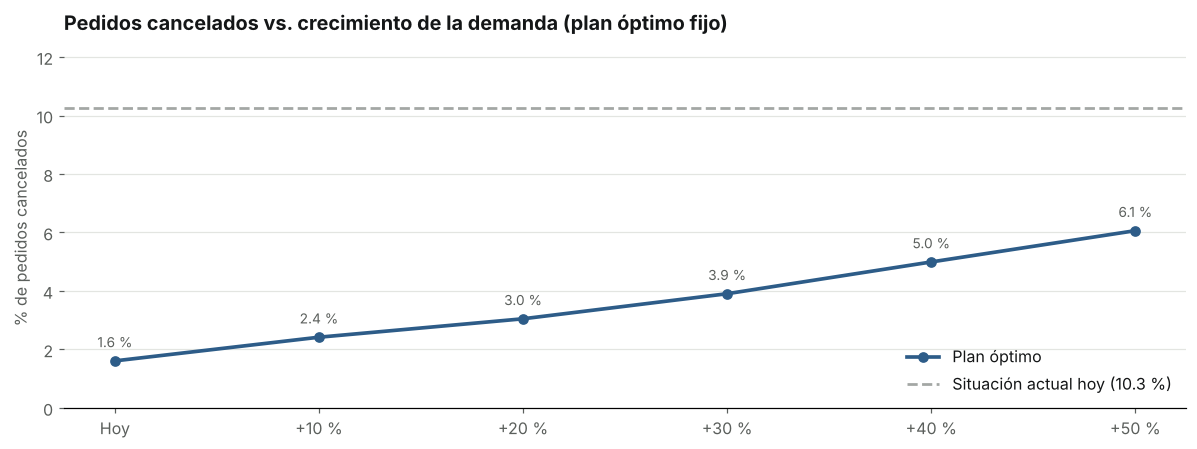

In [14]:
c_pico = personal_por_hora(PLAN_OPTIMO, TURNOS_SIM)[9]          # despachadores a las 9 h en el plan óptimo
crec = []
for g in [0, 0.10, 0.20, 0.30, 0.40, 0.50]:
    r = replicar(PLAN_OPTIMO, T_CAL, P_CAL, crecimiento=g).mean()
    crec.append({"Crecimiento": "Hoy" if g == 0 else f"+{100 * g:.0f} %", "rho pico (9h)": LAMBDA[9] * (1 + g) / (c_pico * MU_H), **r})
crec = pd.DataFrame(crec).set_index("Crecimiento")
display(crec[["rho pico (9h)", "Espera 9-11h (min)", "Pérdida ruta (%)", "Cancelados (%)", "Horas extra (h/año)", "Venta perdida (S/)"]]
        .style.format("{:,.2f}"))

fig, ax = plt.subplots()
ax.plot(crec.index, crec["Cancelados (%)"], marker="o", lw=2.4, color=COLOR["plan"], label="Plan óptimo")
ax.axhline(act["Cancelados (%)"], ls="--", color=COLOR["actual"], lw=1.8, label=f"Situación actual hoy ({act['Cancelados (%)']:.1f} %)")
for i, (g, v) in enumerate(zip(crec.index, crec["Cancelados (%)"])):
    ax.annotate(f"{v:.1f} %", (i, v), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, color=COLOR["tinta2"])
ax.set_ylim(0, max(act["Cancelados (%)"], crec["Cancelados (%)"].max()) * 1.2)
ax.set_title("Pedidos cancelados vs. crecimiento de la demanda (plan óptimo fijo)"); ax.set_ylabel("% de pedidos cancelados"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8. Escenario 3 — Ausentismo

Cada trabajador falta un día con probabilidad dada (independiente). No se reemplaza al ausente.

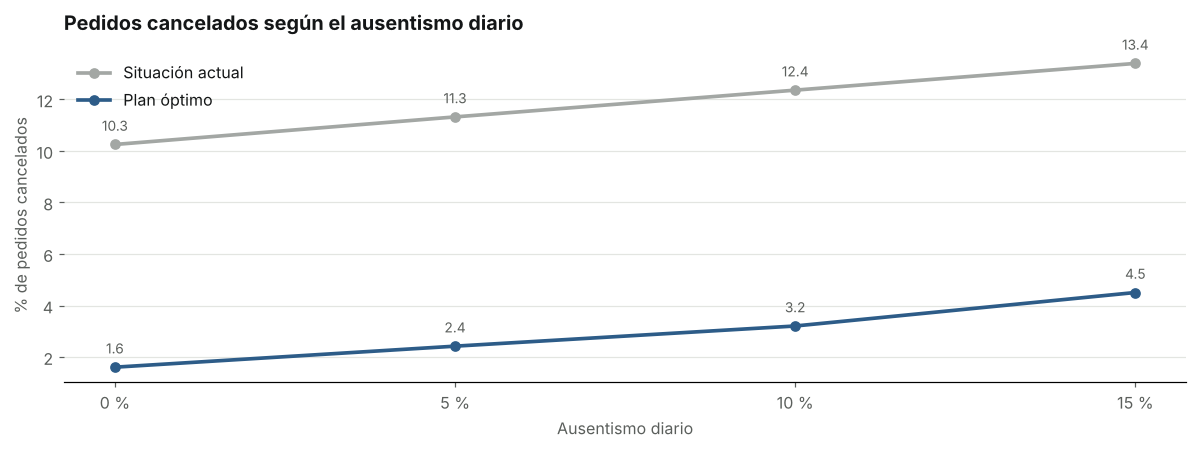

In [15]:
aus = []
for a in [0, 0.05, 0.10, 0.15]:
    for nombre, plan in [("Actual", PLAN_ACTUAL), ("Óptimo", PLAN_OPTIMO)]:
        r = replicar(plan, T_CAL, P_CAL, ausentismo=a).mean()
        aus.append({"Ausentismo (%)": round(100 * a), "Plan": nombre, **r})
aus = pd.DataFrame(aus)
display(aus.pivot(index="Ausentismo (%)", columns="Plan", values=["Cancelados (%)", "Horas extra (h/año)", "Venta perdida (S/)", "Costo total (S/)"])
        .style.format("{:,.2f}"))

fig, ax = plt.subplots()
for nombre, color in [("Actual", COLOR["actual"]), ("Óptimo", COLOR["plan"])]:
    d = aus[aus["Plan"] == nombre]
    ax.plot(d["Ausentismo (%)"], d["Cancelados (%)"], marker="o", lw=2.4, color=color, label="Situación actual" if nombre == "Actual" else "Plan óptimo")
    for xv, yv in zip(d["Ausentismo (%)"], d["Cancelados (%)"]):
        ax.annotate(f"{yv:.1f}", (xv, yv), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=9, color=COLOR["tinta2"])
ax.set_xticks([0, 5, 10, 15], ["0 %", "5 %", "10 %", "15 %"])
ax.set_title("Pedidos cancelados según el ausentismo diario"); ax.set_xlabel("Ausentismo diario"); ax.set_ylabel("% de pedidos cancelados"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

## 9. Escenario 4 — Sensibilidad del $\rho$ objetivo

Para cada $\rho$ objetivo se recalcula $D_h$, se **re-optimiza el MILP** (`optimizar`, el mismo modelo de `Denlu.ipynb`) y se simula el plan resultante. El mejor $\rho$ es el que minimiza **planilla + horas extra + ventas perdidas**.

,Plan,Personas,Cancelados (%),Horas extra (h/año),Planilla anual (S/),Costo horas extra (S/),Margen perdido (S/),Costo total (S/)
rho,,,,,,,,
0.500000,"FT-1:2, FT-2:4, FT-3:1, PT-1:4",11,0.33,132.79,"148,338.48",708.91,"20,203.63","169,251.02"
0.550000,"FT-1:5, FT-3:1, PT-1:4",10,0.23,126.83,"131,856.48",677.08,"13,933.54","146,467.10"
0.600000,"FT-1:5, FT-3:1, PT-1:3",9,0.32,117.26,"123,615.36",626.01,"19,584.37","143,825.74"
0.650000,"FT-1:4, FT-3:1, PT-1:3",8,0.42,127.93,"107,133.36",682.96,"25,777.05","133,593.37"
0.700000,"FT-1:4, FT-3:1, PT-1:3",8,0.42,127.93,"107,133.36",682.96,"25,777.05","133,593.37"
0.750000,"FT-1:4, FT-3:1, PT-1:2",7,0.82,138.89,"98,892.24",741.48,"51,167.06","150,800.78"
0.800000,"FT-1:4, FT-3:1, PT-1:2",7,0.82,138.89,"98,892.24",741.48,"51,167.06","150,800.78"
0.850000,"FT-1:3, FT-3:1, PT-1:2",6,1.61,138.12,"82,410.24",737.37,"99,934.45","183,082.06"
0.900000,"FT-1:3, FT-3:1, PT-1:2",6,1.61,138.12,"82,410.24",737.37,"99,934.45","183,082.06"


rho con menor costo total (margen 100 %): 0.65


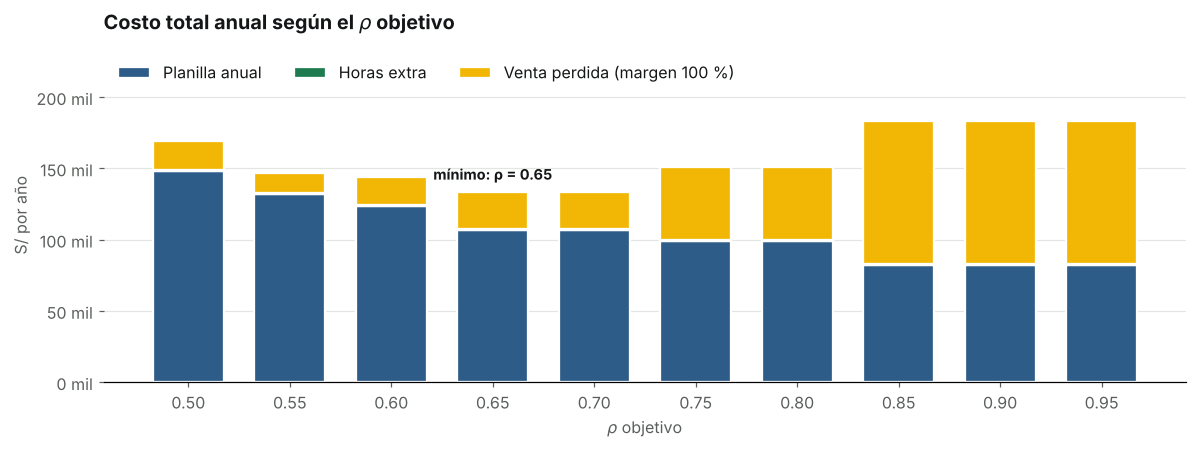

In [16]:
sens = []
for rho_obj in [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95]:
    plan = optimizar(rho_obj)
    r = replicar(plan, T_CAL, P_CAL).mean()
    sens.append({"rho": rho_obj, "Plan": ", ".join(f"{t}:{n}" for t, n in plan.items()), "Personas": sum(plan.values()), **r})
sens = pd.DataFrame(sens).set_index("rho")
columnas = ["Cancelados (%)", "Horas extra (h/año)", "Planilla anual (S/)", "Costo horas extra (S/)", "Margen perdido (S/)", "Costo total (S/)"]
display(sens[["Plan", "Personas", *columnas]].style.format({c: "{:,.2f}" for c in columnas}))
rho_best = sens["Costo total (S/)"].idxmin()
print(f"rho con menor costo total (margen {100 * MARGEN:.0f} %): {rho_best:.2f}")

fig, ax = plt.subplots()
x_rho = [f"{r:.2f}" for r in sens.index]
base_y = np.zeros(len(sens))
for col, color, etiqueta in [("Planilla anual (S/)", COLOR["plan"], "Planilla anual"),
                             ("Costo horas extra (S/)", COLOR["ok"], "Horas extra"),
                             ("Margen perdido (S/)", COLOR["aviso"], f"Venta perdida (margen {100 * MARGEN:.0f} %)")]:
    ax.bar(x_rho, sens[col], bottom=base_y, color=color, label=etiqueta, width=0.7, edgecolor="white", linewidth=1.5)
    base_y = base_y + sens[col].to_numpy()
i_best = list(sens.index).index(rho_best)
ax.annotate(f"mínimo: ρ = {rho_best:.2f}", (i_best, base_y[i_best]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9.5, fontweight="bold")
ax.set_title(r"Costo total anual según el $\rho$ objetivo"); ax.set_xlabel(r"$\rho$ objetivo"); ax.set_ylabel("S/ por año")
ax.yaxis.set_major_formatter(k_soles); ax.set_ylim(0, base_y.max() * 1.28); ax.legend(loc="upper left", ncol=3)
plt.tight_layout(); plt.show()

## 10. ¿Qué $\rho$ conviene según el margen bruto?

Cuando se cancela un pedido, DENLU no pierde toda la venta: pierde el **margen bruto** de ese pedido, porque tampoco gasta en la mercadería que no vendió. El margen no cambia la operación simulada, así que basta con revalorar los resultados del escenario 4:

$$\text{Costo total} = \text{Planilla} + \text{Horas extra} + \text{margen} \times \text{Venta perdida}$$

Margen bruto,rho que minimiza el costo,Plan,Costo total (S/),Ahorro vs rho 0.85 (S/)
10 %,0.85,"FT-1:3, FT-3:1, PT-1:2","93,141",0
20 %,0.85,"FT-1:3, FT-3:1, PT-1:2","103,135",0
30 %,0.85,"FT-1:3, FT-3:1, PT-1:2","113,128",0
40 %,0.65,"FT-1:4, FT-3:1, PT-1:3","118,127","4,994"
50 %,0.65,"FT-1:4, FT-3:1, PT-1:3","120,705","12,410"
75 %,0.65,"FT-1:4, FT-3:1, PT-1:3","127,149","30,949"
100 %,0.65,"FT-1:4, FT-3:1, PT-1:3","133,593","49,489"


El plan de rho 0.65 conviene sobre el de rho 0.85 cuando el margen bruto supera 33 %


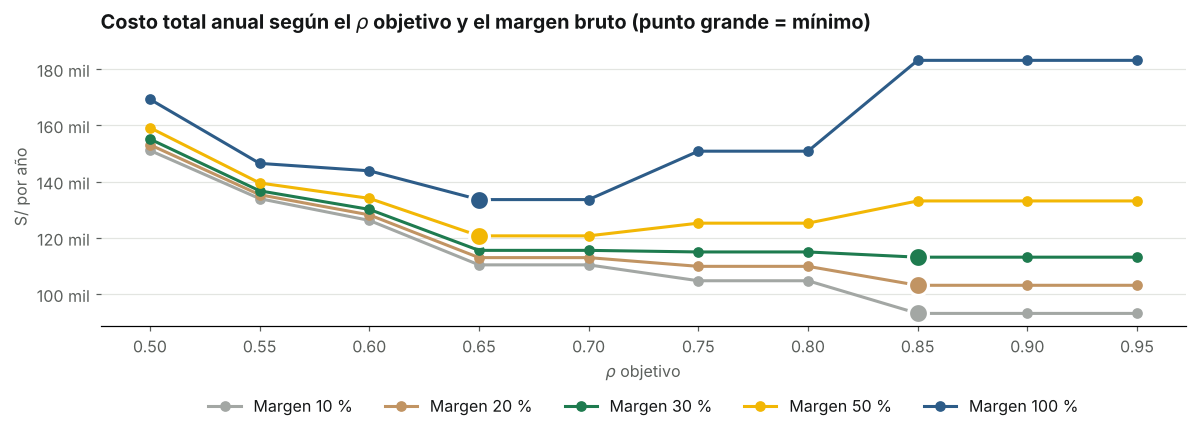

In [17]:
margenes = [0.10, 0.20, 0.30, 0.40, 0.50, 0.75, 1.00]
costo_por_margen = pd.DataFrame({m: sens["Planilla anual (S/)"] + sens["Costo horas extra (S/)"] + m * sens["Venta perdida (S/)"]
                                 for m in margenes})
mejor_rho = costo_por_margen.idxmin()
decision = pd.DataFrame({"Margen bruto": [f"{100 * m:.0f} %" for m in margenes],
                         "rho que minimiza el costo": mejor_rho.values,
                         "Plan": [sens.loc[r, "Plan"] for r in mejor_rho],
                         "Costo total (S/)": costo_por_margen.min().values,
                         f"Ahorro vs rho {RHO_OBJETIVO} (S/)": (costo_por_margen.loc[RHO_OBJETIVO] - costo_por_margen.min()).values})
display(decision.style.format({"rho que minimiza el costo": "{:.2f}", "Costo total (S/)": "{:,.0f}",
                               f"Ahorro vs rho {RHO_OBJETIVO} (S/)": "{:,.0f}"}).hide(axis="index"))

# Margen a partir del cual conviene el plan del mejor rho (a precio de venta) frente al de rho 0.85
rho_alto = rho_best
a, b = sens.loc[rho_alto], sens.loc[RHO_OBJETIVO]
margen_eq = (costo_personal(a) - costo_personal(b)) / (b["Venta perdida (S/)"] - a["Venta perdida (S/)"]) if rho_alto != RHO_OBJETIVO else float("nan")
if rho_alto != RHO_OBJETIVO:
    print(f"El plan de rho {rho_alto:.2f} conviene sobre el de rho {RHO_OBJETIVO} cuando el margen bruto supera {100 * margen_eq:.0f} %")

fig, ax = plt.subplots()
paleta = [COLOR["actual"], COLOR["hist"], COLOR["ok"], COLOR["aviso"], COLOR["plan"]]
for color, m in zip(paleta, [0.10, 0.20, 0.30, 0.50, 1.00]):
    y = costo_por_margen[m]
    ax.plot(x_rho, y, marker="o", lw=2, color=color, label=f"Margen {100 * m:.0f} %")
    ax.plot(f"{y.idxmin():.2f}", y.min(), marker="o", ms=13, color=color, mec="white", mew=2)
ax.set_title(r"Costo total anual según el $\rho$ objetivo y el margen bruto (punto grande = mínimo)")
ax.set_xlabel(r"$\rho$ objetivo"); ax.set_ylabel("S/ por año"); ax.yaxis.set_major_formatter(k_soles); ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.tight_layout(); plt.show()

## 11. Conclusiones

Las cifras de esta sección se calculan con los resultados de los capítulos anteriores: si se cambia un parámetro y se vuelve a ejecutar, el texto se actualiza.

In [18]:
cob_opt = personal_por_hora(PLAN_OPTIMO, TURNOS_SIM)
horas_debiles = [h for h in HORAS if perdida_opt[h] > 10]
g = lambda nombre: crec.loc[nombre]
a10 = aus[(aus["Ausentismo (%)"] == 10)].set_index("Plan")
a15a = aus[(aus["Ausentismo (%)"] == 15)].set_index("Plan")

# ρ que conviene según el margen, agrupando márgenes consecutivos con el mismo mejor ρ
grupos = []
for m, r in mejor_rho.items():
    if grupos and grupos[-1][0] == r: grupos[-1][1].append(m)
    else: grupos.append([r, [m]])
frases_margen = "\n".join(
    f"* Margen bruto de **{100 * ms[0]:.0f} %**{'' if len(ms) == 1 else f' a **{100 * ms[-1]:.0f} %**'}: conviene $\\rho = {r:.2f}$ "
    f"({sens.loc[r, 'Personas']:.0f} despachadores: {sens.loc[r, 'Plan'].replace(':', ' ×').replace(', ', ', ')})."
    for r, ms in grupos)

debil_txt = ""
for h in horas_debiles:
    motivo = ("con un solo despachador cualquier pedido que llega con él ocupado espera, en promedio, un servicio completo "
              f"({MU_MIN} min > T = {T_CAL:.0f} min); $\\rho \\le 0.85$ no garantiza una espera baja cuando hay 1 servidor"
              if cob_opt[h] == 1 else
              f"la capacidad cae de {max(cob_opt.values())} a {cob_opt[h]} despachadores en esa hora (almuerzos o cambio de turno)")
    debil_txt += f"* **{h}:00 h** ({cob_opt[h]} despachador{'es' if cob_opt[h] > 1 else ''}): pérdida de ruta de ≈ {perdida_opt[h]:.0f} % — {motivo}.\n"
if not debil_txt:
    debil_txt = "* Ninguna hora supera el 10 % de pérdida de ruta con el plan óptimo.\n"

display(Markdown(f'''
**Validación.** Con $T = {T_CAL:.0f}$ min y $p = {P_CAL:.2f}$ la operación actual simulada reproduce la pérdida de ruta ({tot_perdida:.1f} % vs {HIST_PERDIDA_TOTAL:.1f} %) y la cancelación ({tot_cancel:.1f} % vs {HIST_CANCEL:.1f} %) de 2025. La simulación muestra además que la cola del pico 9–10 h se arrastra a las horas siguientes, efecto que el análisis $M/M/c$ hora por hora no captura; por hora el ajuste es parcial (capítulo 5).

**1. Actual vs. óptimo.** El plan MILP reduce la espera media de {act['Espera media (min)']:.1f} a {opt['Espera media (min)']:.1f} min y la cancelación de {act['Cancelados (%)']:.1f} % a {opt['Cancelados (%)']:.1f} %. La recuperación real de ventas es **{recuperacion_sim:.0f} %, no el {100 * RECUPERACION_SUPUESTA:.0f} %** del ROI analítico: el beneficio neto es ≈ {soles(beneficio)} al año (ROI ≈ {100 * beneficio / inversion:,.0f} % en lugar de {roi_analitico:,.0f} %), valorando la venta perdida a precio de venta.

**Puntos débiles del plan** (el MILP no los ve porque solo mira $\\rho_h$):

{debil_txt}
**2. Crecimiento.** Con +20 % de demanda el plan tiene una cancelación de {g('+20 %')['Cancelados (%)']:.1f} % ($\\rho$ pico = {g('+20 %')['rho pico (9h)']:.2f}); con +50 %, {g('+50 %')['Cancelados (%)']:.1f} %. La situación actual hoy está en {act['Cancelados (%)']:.1f} %.

**3. Ausentismo.** Con 10 % de ausentismo diario la cancelación del plan óptimo sube a {a10.loc['Óptimo', 'Cancelados (%)']:.1f} %, frente a {a10.loc['Actual', 'Cancelados (%)']:.1f} % del sistema actual. Conviene tener un reemplazo o polivalencia para las 9–11 h.

**4. Horas extra.** Despachar lo pendiente después de las 18:00 cuesta poco: ≈ {act['Horas extra (h/año)']:.0f} h/año en la situación actual y {opt['Horas extra (h/año)']:.0f} h/año con el plan óptimo (≈ {soles(opt['Costo horas extra (S/)'])} al año, {100 * opt['Costo horas extra (S/)'] / opt['Planilla anual (S/)']:.1f} % de la planilla). Sube con el ausentismo ({a15a.loc['Actual', 'Horas extra (h/año)']:.0f} h/año en la situación actual con 15 %), pero no cambia la decisión.

**5. $\\rho$ objetivo y margen bruto.** La decisión depende de cómo se valore un pedido cancelado:

{frases_margen}

{f'El plan de $\\rho = {rho_alto:.2f}$ supera al de $\\rho = {RHO_OBJETIVO}$ cuando el margen bruto pasa de ≈ {100 * margen_eq:.0f} %. ' if rho_alto != RHO_OBJETIVO else ''}En una distribuidora mayorista el margen bruto suele ser bajo, así que lo más probable es que $\\rho = {RHO_OBJETIVO}$ siga siendo la mejor opción; conviene confirmarlo con el margen real de DENLU.

**Limitaciones.** Servicio exponencial y ticket constante, situación actual sin almuerzos, días independientes (lo pendiente no pasa al día siguiente) y ajuste solo parcial al patrón horario del histórico (capítulo 5). Solo se pagan como extra las horas posteriores a las 18:00: terminar un pedido después del fin de un turno individual (p. ej. FT-1 a las 17:00) no se cuenta, y se aplica el 25 % de sobretasa a todas las horas extra (desde la tercera hora del día la ley exige 35 %).
'''))


**Validación.** Con $T = 20$ min y $p = 0.28$ la operación actual simulada reproduce la pérdida de ruta (36.6 % vs 36.4 %) y la cancelación (10.3 % vs 10.0 %) de 2025. La simulación muestra además que la cola del pico 9–10 h se arrastra a las horas siguientes, efecto que el análisis $M/M/c$ hora por hora no captura; por hora el ajuste es parcial (capítulo 5).

**1. Actual vs. óptimo.** El plan MILP reduce la espera media de 20.3 a 3.1 min y la cancelación de 10.3 % a 1.6 %. La recuperación real de ventas es **84 %, no el 95 %** del ROI analítico: el beneficio neto es ≈ S/ 501,675 al año (ROI ≈ 1,521 % en lugar de 1,687 %), valorando la venta perdida a precio de venta.

**Puntos débiles del plan** (el MILP no los ve porque solo mira $\rho_h$):

* **12:00 h** (3 despachadores): pérdida de ruta de ≈ 14 % — la capacidad cae de 6 a 3 despachadores en esa hora (almuerzos o cambio de turno).
* **17:00 h** (1 despachador): pérdida de ruta de ≈ 38 % — con un solo despachador cualquier pedido que llega con él ocupado espera, en promedio, un servicio completo (44.5 min > T = 20 min); $\rho \le 0.85$ no garantiza una espera baja cuando hay 1 servidor.

**2. Crecimiento.** Con +20 % de demanda el plan tiene una cancelación de 3.0 % ($\rho$ pico = 1.00); con +50 %, 6.1 %. La situación actual hoy está en 10.3 %.

**3. Ausentismo.** Con 10 % de ausentismo diario la cancelación del plan óptimo sube a 3.2 %, frente a 12.4 % del sistema actual. Conviene tener un reemplazo o polivalencia para las 9–11 h.

**4. Horas extra.** Despachar lo pendiente después de las 18:00 cuesta poco: ≈ 134 h/año en la situación actual y 138 h/año con el plan óptimo (≈ S/ 737 al año, 0.9 % de la planilla). Sube con el ausentismo (271 h/año en la situación actual con 15 %), pero no cambia la decisión.

**5. $\rho$ objetivo y margen bruto.** La decisión depende de cómo se valore un pedido cancelado:

* Margen bruto de **10 %** a **30 %**: conviene $\rho = 0.85$ (6 despachadores: FT-1 ×3, FT-3 ×1, PT-1 ×2).
* Margen bruto de **40 %** a **100 %**: conviene $\rho = 0.65$ (8 despachadores: FT-1 ×4, FT-3 ×1, PT-1 ×3).

El plan de $\rho = 0.65$ supera al de $\rho = 0.85$ cuando el margen bruto pasa de ≈ 33 %. En una distribuidora mayorista el margen bruto suele ser bajo, así que lo más probable es que $\rho = 0.85$ siga siendo la mejor opción; conviene confirmarlo con el margen real de DENLU.

**Limitaciones.** Servicio exponencial y ticket constante, situación actual sin almuerzos, días independientes (lo pendiente no pasa al día siguiente) y ajuste solo parcial al patrón horario del histórico (capítulo 5). Solo se pagan como extra las horas posteriores a las 18:00: terminar un pedido después del fin de un turno individual (p. ej. FT-1 a las 17:00) no se cuenta, y se aplica el 25 % de sobretasa a todas las horas extra (desde la tercera hora del día la ley exige 35 %).


## Anexo — Parámetros que usa el simulador web

El simulador interactivo (`Simulacion/web/`) reimplementa este mismo modelo en JavaScript. Estos son los valores que debe tener y que `node verificar.js` comprueba contra el notebook.

In [19]:
PLANES_WEB = {0.85: {"FT-1": 3, "FT-3": 1, "PT-1": 2}, 0.75: {"FT-1": 4, "FT-3": 1, "PT-1": 2}, 0.65: {"FT-1": 4, "FT-3": 1, "PT-1": 3}}
anexo = []
for rho_obj, plan_web in PLANES_WEB.items():
    plan_nb = optimizar(rho_obj)
    anexo.append({"rho": rho_obj, "Plan (MILP)": ", ".join(f"{t} ×{n}" for t, n in plan_nb.items()),
                  "Planilla (S/ mes)": costo_mensual(plan_nb), "Coincide con el simulador web": "sí" if plan_nb == plan_web else "NO"})
display(pd.DataFrame(anexo).style.hide(axis="index").format({"Planilla (S/ mes)": "{:,.2f}", "rho": "{:.2f}"}))
print(f"T = {T_CAL:.0f} min | p = {P_CAL:.2f} | ticket = S/ {TICKET:,.2f} | hora extra = S/ {COSTO_HORA_EXTRA:.2f} | {DIAS} días | {R} réplicas")

rho,Plan (MILP),Planilla (S/ mes),Coincide con el simulador web
0.85,"FT-1 ×3, FT-3 ×1, PT-1 ×2","6,867.52",sí
0.75,"FT-1 ×4, FT-3 ×1, PT-1 ×2","8,241.02",sí
0.65,"FT-1 ×4, FT-3 ×1, PT-1 ×3","8,927.78",sí


T = 20 min | p = 0.28 | ticket = S/ 774.09 | hora extra = S/ 5.34 | 299 días | 10 réplicas
